# Does Money Make People Happy? 💰🙂
### Predicting life satisfaction from GDP per capita — Mini Project 01

*Based on Chapter 1 ("The Machine Learning Landscape") of* **Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow (3rd ed.)** *by Aurélien Géron.*

---

**The question:** If we know how rich a country is (its GDP per capita), can we predict how satisfied its people are with their lives?

**What this notebook does, step by step:**
1. Load and look at real data (OECD life satisfaction + World Bank GDP)
2. Train our first model: **Linear Regression**
3. Train a second model: **k-Nearest Neighbors**
4. Use both models to make a prediction for **Cyprus** (a country that is *not* in our data)
5. Learn three of the most important ideas in Machine Learning:
   - why the training data must be **representative**
   - what **overfitting** looks like
   - how **regularization** helps

> 💡 **Tip for reading this notebook:** Run the cells one by one from top to bottom (`Shift + Enter`). Read the text above each cell *before* you run it, then look at the output.

## 1. Import the libraries

A *library* is a collection of ready-made code that other people wrote, so we don't have to write everything ourselves.

| Library | Short name | What we use it for |
|---|---|---|
| `pandas` | `pd` | Working with tables of data (like Excel in Python) |
| `numpy` | `np` | Fast math with numbers and arrays |
| `matplotlib.pyplot` | `plt` | Drawing plots |
| `sklearn` (Scikit-Learn) | – | The Machine Learning models |

The `as pd` part just gives the library a short nickname, so we can write `pd` instead of `pandas` every time.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

print("All libraries imported successfully!")

All libraries imported successfully!


A few small settings so the plots look nice, plus a helper function that saves every plot into an `images/` folder. The saved images are shown in the project's README on GitHub.

In [2]:
# Make the plot text a bit bigger and easier to read
plt.rc("font", size=12)
plt.rc("axes", labelsize=13, titlesize=14)

# Create the folder "images" (if it does not exist yet)
IMAGES_PATH = Path("images")
IMAGES_PATH.mkdir(exist_ok=True)

def save_fig(name):
    """Save the current plot as a PNG file in the images/ folder."""
    plt.tight_layout()
    plt.savefig(IMAGES_PATH / f"{name}.png", dpi=150)

## 2. Load the data

The data is stored as a **CSV file** (Comma-Separated Values) — a simple text table. Aurélien Géron prepared it from two sources:
- **Life satisfaction** (a score from 0 to 10) from the OECD *Better Life Index*, year 2020
- **GDP per capita** (in US dollars) from the World Bank, year 2020

`pd.read_csv()` downloads the file and turns it into a **DataFrame** (a table).

In [3]:
DATA_URL = "https://raw.githubusercontent.com/ageron/data/main/lifesat/"

lifesat = pd.read_csv(DATA_URL + "lifesat.csv")

# Show the first 5 rows of the table
lifesat.head()

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6


## 3. Explore the data

Before training any model, **always look at your data first**. Let's answer a few simple questions:
- How many rows (countries) and columns are there?
- What are the smallest, largest and average values?

In [4]:
print("Shape (rows, columns):", lifesat.shape)
print("Number of countries:", len(lifesat))

Shape (rows, columns): (27, 3)
Number of countries: 27


In [5]:
# describe() gives a quick statistical summary of every number column
lifesat.describe().round(2)

,GDP per capita (USD),Life satisfaction
count,27.00,27.00
mean,41564.52,6.57
std,9631.45,0.77
min,26456.39,5.40
25%,33938.29,5.90
50%,41627.13,6.80
75%,49690.58,7.30
max,60235.73,7.60


**How to read this table:**
- `count` → how many values
- `mean` → the average
- `std` → standard deviation (how spread out the values are)
- `min` / `max` → smallest / largest value
- `25%`, `50%`, `75%` → quartiles (`50%` is the median)

Which countries are the richest and the least rich in our data?

In [6]:
lifesat.sort_values("GDP per capita (USD)", ascending=False).head()

,Country,GDP per capita (USD),Life satisfaction
26,United States,60235.728492,6.9
25,Denmark,55938.212809,7.6
24,Netherlands,54209.563836,7.4
23,Iceland,52279.728851,7.5
22,Austria,51935.603862,7.1


In [7]:
lifesat.sort_values("GDP per capita (USD)").head()

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6


## 4. Visualize the data

A **scatter plot** shows every country as one dot:
- x-axis (horizontal) → GDP per capita
- y-axis (vertical) → life satisfaction

👀 **Question to think about:** Do you see a pattern? When GDP goes up, what happens to life satisfaction?

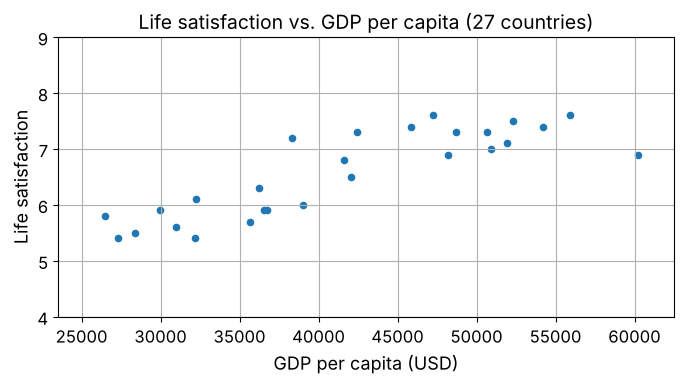

In [8]:
lifesat.plot(kind="scatter", x="GDP per capita (USD)", y="Life satisfaction",
             grid=True, figsize=(7, 4))
plt.title("Life satisfaction vs. GDP per capita (27 countries)")
plt.axis([23_500, 62_500, 4, 9])   # [x_min, x_max, y_min, y_max]
save_fig("01_scatter_data")
plt.show()

There is a clear trend: **richer countries tend to have higher life satisfaction**. The points lie roughly along a straight line (with some noise). That suggests a straight line could be a good model.

> 💡 Numbers like `23_500` are the same as `23500`. Python allows the underscore `_` to make big numbers easier to read.

## 5. Prepare the data for Scikit-Learn

Scikit-Learn needs two things:
- **`X`** → the *features* (the input). Here: GDP per capita.
- **`y`** → the *target* / *label* (what we want to predict). Here: life satisfaction.

⚠️ Scikit-Learn expects `X` to be a **2D table** (rows × columns), even if we have only one feature. That is why we use **double brackets** `[["..."]]`:
- `lifesat["GDP per capita (USD)"]` → single brackets → 1D (one simple list)
- `lifesat[["GDP per capita (USD)"]]` → double brackets → 2D (a table with one column)

`.values` converts the pandas table into a NumPy array.

In [9]:
X = lifesat[["GDP per capita (USD)"]].values
y = lifesat[["Life satisfaction"]].values

print("Shape of X:", X.shape)   # (27, 1) → 27 rows, 1 column
print("Shape of y:", y.shape)
print("First 3 values of X:", X[:3].ravel())

Shape of X: (27, 1)
Shape of y: (27, 1)
First 3 values of X: [26456.38793813 27287.08340093 28384.98778463]


## 6. Model 1 — Linear Regression

A **linear model** assumes the relationship is a straight line:

$$\text{life satisfaction} = \theta_0 + \theta_1 \times \text{GDP per capita}$$

- $\theta_0$ (theta zero) → the **intercept**: where the line crosses the y-axis
- $\theta_1$ (theta one) → the **slope**: how much life satisfaction goes up for each extra dollar

**Training** the model means: find the values of $\theta_0$ and $\theta_1$ that make the line fit the data as well as possible.

Every Scikit-Learn model is used in the same 3 steps:
1. **Create** the model → `model = LinearRegression()`
2. **Train** it on the data → `model.fit(X, y)`
3. **Predict** new values → `model.predict(X_new)`

In [10]:
# Step 1: create the model
lin_model = LinearRegression()

# Step 2: train (fit) the model on our data
lin_model.fit(X, y)

# Look at the parameters the model learned
theta0 = lin_model.intercept_[0]
theta1 = lin_model.coef_[0][0]

print(f"θ0 (intercept) = {theta0:.4f}")
print(f"θ1 (slope)     = {theta1:.10f}")
print(f"→ Every extra 10,000 USD of GDP adds about {theta1 * 10_000:.2f} points of life satisfaction.")

θ0 (intercept) = 3.7490
θ1 (slope)     = 0.0000677890
→ Every extra 10,000 USD of GDP adds about 0.68 points of life satisfaction.


### Make a prediction for Cyprus 🇨🇾

Cyprus is **not** in our data. Its GDP per capita in 2020 was **37,655.2 USD**. What life satisfaction does our model predict?

Note: `X_new` must again be 2D → `[[37_655.2]]` (a list inside a list).

`predict()` returns the answer inside an array, e.g. `[[6.30]]`. `.item()` takes the single number out of the array, so we get just `6.30`.

In [11]:
X_new = [[37_655.2]]   # Cyprus' GDP per capita in 2020

# Step 3: predict
cyprus_pred_lin = lin_model.predict(X_new).item()
print(f"Linear Regression predicts for Cyprus: {cyprus_pred_lin:.2f}")

Linear Regression predicts for Cyprus: 6.30


Let's draw the learned line on top of the data, and mark the Cyprus prediction in red.

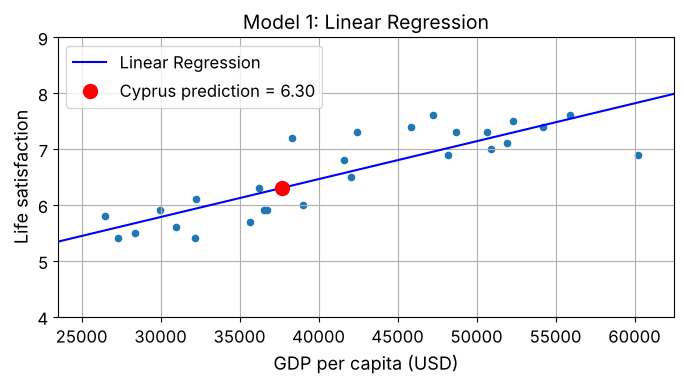

In [12]:
x_line = np.linspace(23_500, 62_500, 100).reshape(-1, 1)   # 100 GDP values, evenly spaced
y_line = lin_model.predict(x_line)

lifesat.plot(kind="scatter", x="GDP per capita (USD)", y="Life satisfaction",
             grid=True, figsize=(7, 4))
plt.plot(x_line, y_line, "b-", label="Linear Regression")
plt.plot(37_655.2, cyprus_pred_lin, "ro", markersize=10, label=f"Cyprus prediction = {cyprus_pred_lin:.2f}")
plt.title("Model 1: Linear Regression")
plt.axis([23_500, 62_500, 4, 9])
plt.legend(loc="upper left")
save_fig("02_linear_regression")
plt.show()

## 7. Model 2 — k-Nearest Neighbors (k = 3)

This model works in a completely different way. It does **not** learn a line. Instead, it **remembers all the data**. To make a prediction, it:
1. finds the **3 countries** whose GDP is **closest** to Cyprus' GDP
2. returns the **average** of their life satisfaction

This is called **instance-based learning** (Linear Regression is **model-based learning**).

Notice: we use exactly the same 3 steps — only the first line changes!

In [13]:
knn_model = KNeighborsRegressor(n_neighbors=3)   # Step 1: create
knn_model.fit(X, y)                              # Step 2: train
cyprus_pred_knn = knn_model.predict(X_new).item() # Step 3: predict

print(f"k-Nearest Neighbors predicts for Cyprus: {cyprus_pred_knn:.2f}")

k-Nearest Neighbors predicts for Cyprus: 6.33


Which 3 countries did the model use? `kneighbors()` tells us the positions (indices) of the closest rows. Let's look them up:

In [14]:
distances, indices = knn_model.kneighbors(X_new)

neighbors = lifesat.iloc[indices[0]].copy()
neighbors["Distance to Cyprus (USD)"] = distances[0].round(0)
neighbors

,Country,GDP per capita (USD),Life satisfaction,Distance to Cyprus (USD)
11,Israel,38341.307570,7.2,686.0
10,Lithuania,36732.034744,5.9,923.0
9,Slovenia,36547.738956,5.9,1107.0


In [15]:
print("Average life satisfaction of these 3 countries:",
      round(neighbors["Life satisfaction"].mean(), 2))

Average life satisfaction of these 3 countries: 6.33


✅ That is exactly the k-NN prediction — the model simply averaged its 3 nearest neighbors.

### Compare the two models

In [16]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "k-Nearest Neighbors (k=3)"],
    "Prediction for Cyprus": [round(cyprus_pred_lin, 2), round(cyprus_pred_knn, 2)],
})
comparison

,Model,Prediction for Cyprus
0,Linear Regression,6.30
1,k-Nearest Neighbors (k=3),6.33


Both models give a similar answer (about **6.3**). This makes us more confident in the prediction.

---
# Part 2 — Three important lessons from Chapter 1

So far we used only 27 countries with GDP between 23,500 and 62,500 USD. Géron removed the poorest and the richest countries **on purpose**, to show what can go wrong.

## 8. Lesson 1 — The training data must be representative

Let's load the **full** dataset, which also includes the missing countries.

In [17]:
lifesat_full = pd.read_csv(DATA_URL + "lifesat_full.csv")
print("Countries in the full dataset:", len(lifesat_full))

# Which countries were missing from our first dataset?
missing = lifesat_full[~lifesat_full["Country"].isin(lifesat["Country"])]
missing

Countries in the full dataset: 36


,Country,GDP per capita (USD),Life satisfaction
0,South Africa,11466.189672,4.7
1,Colombia,13441.492952,6.3
2,Brazil,14063.982505,6.4
3,Mexico,17887.750736,6.5
4,Chile,23324.524751,6.5
32,Norway,63585.903514,7.6
33,Switzerland,68393.306004,7.5
34,Ireland,89688.956958,7.0
35,Luxembourg,110261.157353,6.9


> 💡 `isin()` checks if each country is in the small dataset. The `~` sign means **NOT**. So this line keeps the countries that are **not** in the small dataset.

Now we train a second Linear Regression on **all** countries and compare both lines.

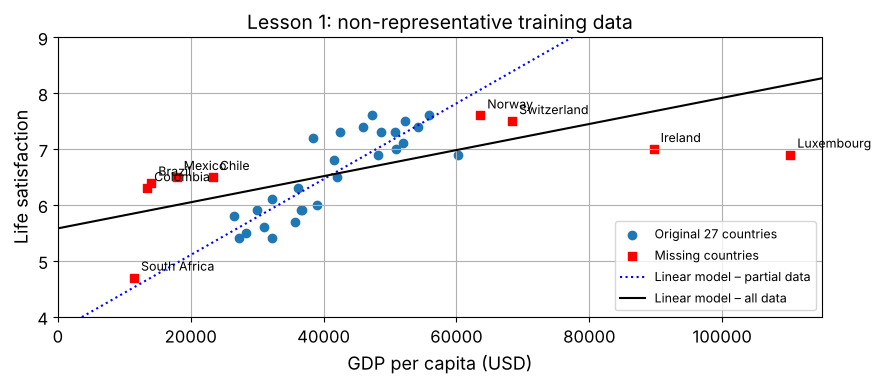

Slope with partial data: 6.78e-05
Slope with all data:     2.33e-05


In [18]:
X_full = lifesat_full[["GDP per capita (USD)"]].values
y_full = lifesat_full[["Life satisfaction"]].values

lin_model_full = LinearRegression()
lin_model_full.fit(X_full, y_full)

x_wide = np.linspace(0, 115_000, 200).reshape(-1, 1)

plt.figure(figsize=(9, 4))
plt.scatter(lifesat["GDP per capita (USD)"], lifesat["Life satisfaction"], label="Original 27 countries")
plt.scatter(missing["GDP per capita (USD)"], missing["Life satisfaction"], color="red", marker="s", label="Missing countries")
plt.plot(x_wide, lin_model.predict(x_wide), "b:", label="Linear model – partial data")
plt.plot(x_wide, lin_model_full.predict(x_wide), "k-", label="Linear model – all data")
for _, row in missing.iterrows():
    plt.annotate(row["Country"], (row["GDP per capita (USD)"], row["Life satisfaction"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("Lesson 1: non-representative training data")
plt.axis([0, 115_000, 4, 9])
plt.grid(True)
plt.legend(loc="lower right", fontsize=9)
save_fig("03_representative_data")
plt.show()

print(f"Slope with partial data: {lin_model.coef_[0][0]:.2e}")
print(f"Slope with all data:     {lin_model_full.coef_[0][0]:.2e}")

**What we learn:** The missing countries do **not** follow the same line. Some poorer countries (e.g. Colombia, Mexico) are happier than the first model predicts, and very rich countries (e.g. Luxembourg, Ireland) are not happier than Switzerland or Norway.

👉 A model trained on non-representative data can make **bad predictions** for cases it has never seen. Money seems to help up to a point, but the relationship is not a straight line forever.

## 9. Lesson 2 — Overfitting

What if we use a much more **complex** model — a curve instead of a straight line? Here we use a **polynomial of degree 10** (a very wiggly curve).

A **Pipeline** chains several steps together:
1. `PolynomialFeatures` → creates GDP, GDP², GDP³, … up to GDP¹⁰
2. `StandardScaler` → scales these numbers to a similar size (otherwise GDP¹⁰ would be enormous)
3. `LinearRegression` → fits the model

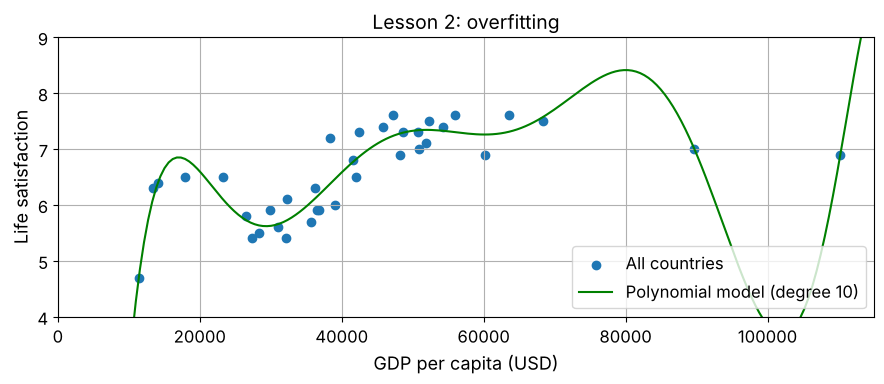

In [19]:
poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=10, include_bias=False)),
    ("scaler", StandardScaler()),
    ("lin_reg", LinearRegression()),
])
poly_model.fit(X_full, y_full)

plt.figure(figsize=(9, 4))
plt.scatter(X_full, y_full, label="All countries")
plt.plot(x_wide, poly_model.predict(x_wide), "g-", label="Polynomial model (degree 10)")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("Lesson 2: overfitting")
plt.axis([0, 115_000, 4, 9])
plt.grid(True)
plt.legend(loc="lower right")
save_fig("04_overfitting")
plt.show()

**What we learn:** The curve passes very close to the training points, so it looks "good" on the training data. But between and beyond the points it makes **crazy jumps** that make no sense in the real world.

👉 This is **overfitting**: the model learned the *noise* in the data instead of the real pattern. It will make bad predictions on new data. More complex is **not** always better.

## 10. Lesson 3 — Regularization

**Regularization** means *constraining* a model to keep it simpler, so it overfits less.

`Ridge` is a Linear Regression with regularization. It punishes large parameter values. The parameter `alpha` controls how strong the punishment is (bigger `alpha` → simpler model → flatter line).

We train it on the **partial** data again (27 countries) and compare it with the earlier lines.

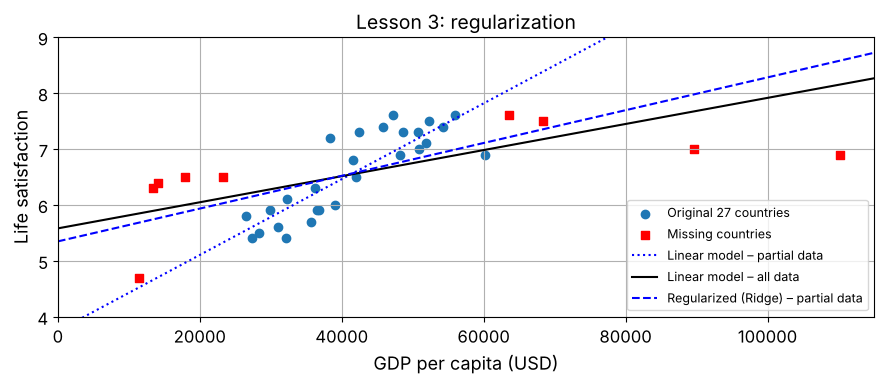

In [20]:
ridge_model = Ridge(alpha=10**9.5)   # a very large alpha, because our GDP values are very large numbers
ridge_model.fit(X, y)

plt.figure(figsize=(9, 4))
plt.scatter(lifesat["GDP per capita (USD)"], lifesat["Life satisfaction"], label="Original 27 countries")
plt.scatter(missing["GDP per capita (USD)"], missing["Life satisfaction"], color="red", marker="s", label="Missing countries")
plt.plot(x_wide, lin_model.predict(x_wide), "b:", label="Linear model – partial data")
plt.plot(x_wide, lin_model_full.predict(x_wide), "k-", label="Linear model – all data")
plt.plot(x_wide, ridge_model.predict(x_wide), "b--", label="Regularized (Ridge) – partial data")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("Lesson 3: regularization")
plt.axis([0, 115_000, 4, 9])
plt.grid(True)
plt.legend(loc="lower right", fontsize=9)
save_fig("05_regularization")
plt.show()

**What we learn:** The regularized line (dashed) is **flatter** than the normal line trained on the same partial data (dotted). It is closer to the line trained on *all* countries (solid black), even though it never saw the missing countries.

👉 Regularization helps the model **generalize** better to new data.

In [21]:
summary = pd.DataFrame({
    "Model": [
        "Linear Regression (27 countries)",
        "k-NN, k=3 (27 countries)",
        "Linear Regression (all countries)",
        "Ridge (27 countries)",
    ],
    "Prediction for Cyprus": [
        lin_model.predict(X_new).item(),
        knn_model.predict(X_new).item(),
        lin_model_full.predict(X_new).item(),
        ridge_model.predict(X_new).item(),
    ],
}).round(2)
summary

,Model,Prediction for Cyprus
0,Linear Regression (27 countries),6.30
1,"k-NN, k=3 (27 countries)",6.33
2,Linear Regression (all countries),6.46
3,Ridge (27 countries),6.45


## 11. Summary — what I learned

| Concept | In one sentence |
|---|---|
| **Supervised learning** | We train a model on examples where we know the answer (the label). |
| **Regression** | Predicting a number (here: life satisfaction). |
| **Model-based learning** | The model learns parameters (θ0, θ1) – e.g. Linear Regression. |
| **Instance-based learning** | The model remembers the data and compares new cases to it – e.g. k-NN. |
| **Scikit-Learn workflow** | `model = ...` → `model.fit(X, y)` → `model.predict(X_new)` |
| **Representative data** | If the training data misses important cases, predictions can be wrong. |
| **Overfitting** | A too-complex model learns noise and fails on new data. |
| **Regularization** | Constraining the model (e.g. `Ridge`) reduces overfitting. |

### Ideas to try yourself
- Change `n_neighbors=3` to `1`, `5` or `10`. How does the Cyprus prediction change?
- Change the polynomial `degree=10` to `2` or `3`. Does it still overfit?
- Try different `alpha` values for `Ridge` (e.g. `10**8`, `10**10`).
- Predict life satisfaction for another country, e.g. Germany (GDP ≈ 46,000 USD in 2020).

---
*Next mini project: Chapter 2 – an end-to-end Machine Learning project (California housing prices).*